In [1]:
import sys
import torch
import numpy as np
import matplotlib.pyplot as plt

sys.path.append("..")
from lib_pca.utils_sqrtm import sqrtm
from lib_pca.utils_plot import draw_cov
from lib_pca.lifted_pca import LiftedPCA
from lib_pca.uncertainty_aware_pca import UAPCA

[KeOps] Warning : CUDA libraries not found or could not be loaded; Switching to CPU only.


In [2]:
def plot(eig_lifted, eig_distr_pca, samples, means, Sigmas, title=None, weights=None, bary_lifted_pca=None):

    if weights is None:
        weights = np.ones(len(eig_lifted))
    weights = np.asarray(weights, dtype=float)

    max_weight = weights.max()
    if max_weight > 0:
        # Scale by the absolute maximum to avoid exaggerating tiny differences.
        alpha = 0.2 + 0.8 * weights / max_weight
        alpha = np.clip(alpha, 0.0, 1.0)
    else:
        alpha = np.ones_like(weights)

    index_max_alpha = np.argmax(alpha)

    for k in range(len(samples)):
        plt.scatter(samples[k][:, 0], samples[k][:,1], alpha=0.1)
        draw_cov(means[k], Sigmas[k], nstd=1)
    
    plt.scatter(means[:, 0], means[:, 1], marker="x", s=100, c="k")
    
    ts = torch.linspace(-5, 5, 100)

    if bary_lifted_pca is not None:
        pc = ts[:,None] * bary_lifted_pca[0][None]
        plt.plot(pc[:,0], pc[:,1], c="orange", lw=2, label="Barycenter Lifted PCA")

    pc = ts[:,None] * eig_distr_pca[:,0][None]
    plt.plot(pc[:,0], pc[:,1], c="black", label="UAPCA")
    
    for k in range(len(eig_lifted)):
        pc = ts[:,None] * eig_lifted[k,:,0][None]
        line_kwargs = {
            "c": "orange",
            "alpha": alpha[k],
            "lw": 0.8 + alpha[k],
            "zorder": 3,
        }

        if k == index_max_alpha:
            line_kwargs.update({"lw": 2.2, "label": "Lifted PCA"})

        plt.plot(pc[:,0], pc[:,1], **line_kwargs)

    if title is not None:
        plt.title(title)

    plt.legend()
    
    plt.xlim(-5, 5)
    plt.ylim(-5, 5)
    plt.show()

## Example of Niculae

In [3]:
## Data from https://arxiv.org/abs/2306.13503

m1, m2, m3, m4 = [-0.5, -2], [0.5, -1], [-0.5, 0], [0.5, 1]
means = torch.tensor([m1, m2, m3, m4])

Sigma = torch.diag(torch.tensor([1, 0.5]))
Sigmas = torch.stack([Sigma for i in range(len(means))])

n = 1000
d = 2
samples = torch.zeros((len(means), n, d))
for k in range(len(means)):
    samples[k] = means[k] + torch.randn(n, d) @ sqrtm(Sigmas[k])

INFO:2026-10-15 17:12:45,245:jax._src.xla_bridge:812: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
INFO: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory


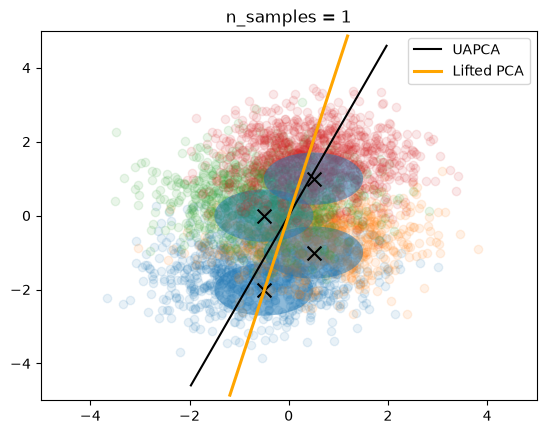

n=1 LiftedPCA 1.1495389938354492 UAPCA 1.1291184425354004
tensor([[-0.0032, -0.5120]]) tensor([[-0.0032, -0.5120]])


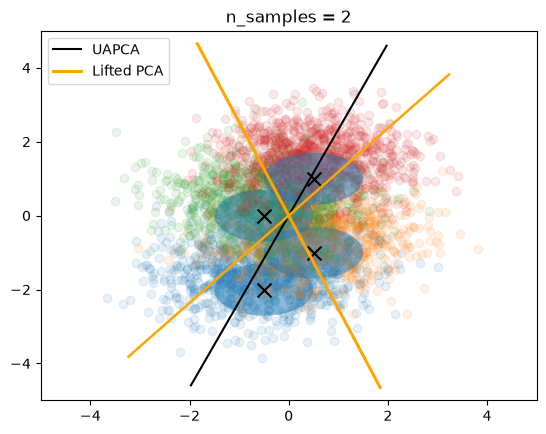

n=2 LiftedPCA 0.5220807790756226 UAPCA 1.1291184425354004
tensor([[-0.0032, -0.5120]]) tensor([[-0.0032, -0.5120]])


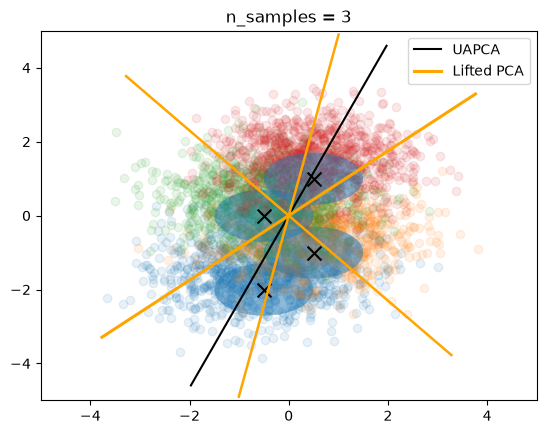

n=3 LiftedPCA 0.3075198531150818 UAPCA 1.1291184425354004
tensor([[-0.0032, -0.5120]]) tensor([[-0.0032, -0.5120]])


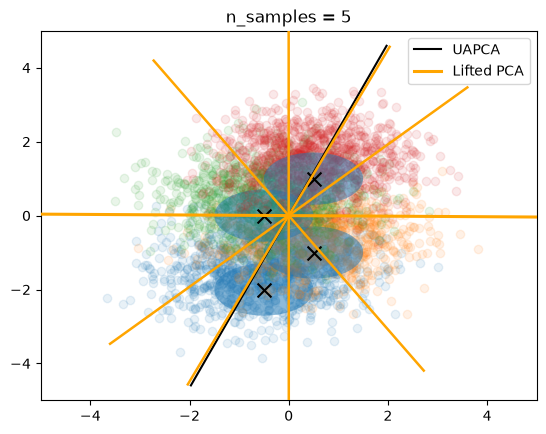

n=5 LiftedPCA 0.16568319499492645 UAPCA 1.1291184425354004
tensor([[-0.0032, -0.5120]]) tensor([[-0.0032, -0.5120]])


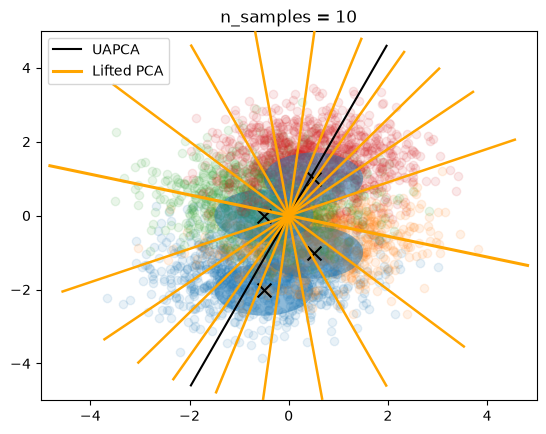

n=10 LiftedPCA 0.09126923978328705 UAPCA 1.1291184425354004
tensor([[-0.0032, -0.5120]]) tensor([[-0.0032, -0.5120]])


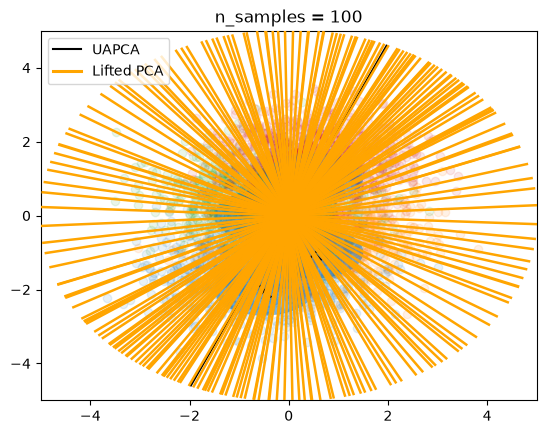

n=100 LiftedPCA 0.06301248073577881 UAPCA 1.1291184425354004
tensor([[-0.0032, -0.5120]]) tensor([[-0.0032, -0.5120]])


In [4]:
# Vary number of Dirac
for n_samples in [1, 2, 3, 5, 10, 100]:
    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.fit(samples)
    eigenvectors_lifted = lifted_pca.components_
    
    # Distributional PCA
    pca_distributional = UAPCA()
    pca_distributional.fit_from_samples(samples)
    eigenvectors_distributional = pca_distributional.components_# .numpy()

    plot(eigenvectors_lifted, eigenvectors_distributional, lifted_pca.center_data(samples), means, Sigmas, title="n_samples = "+str(n_samples))

    print(
        "n="+str(n_samples), "LiftedPCA", lifted_pca.cost_barycenter(samples).item(),
        "UAPCA", pca_distributional.cost_barycenter(samples).item()
    )

    print(lifted_pca.mean_, pca_distributional.mean_)

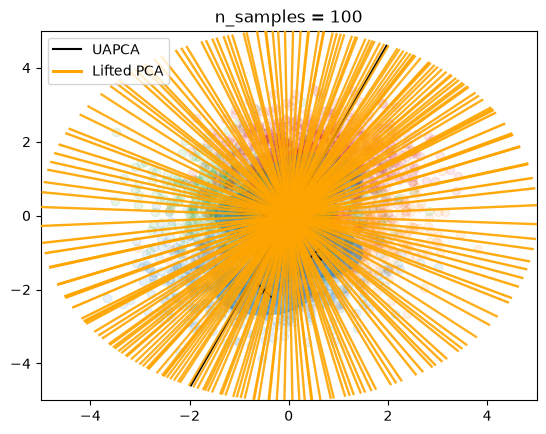

Barycenter cost: 0.06100079417228699


In [5]:
# Fix the support and optim over weights only (with good initialization)
lifted_pca = LiftedPCA(n_components=1, n_samples=100)
lifted_pca.fit(samples, eigenvectors_lifted, solver="fixed_support", seed=42, n_iter_bary=1000, stop_threshold_fixed_support=1e-20)
eigenvectors_lifted = lifted_pca.components_

# Distributional PCA
pca_distributional = UAPCA()
pca_distributional.fit_from_samples(samples)
eigenvectors_distributional = pca_distributional.components_# .numpy()

plot(eigenvectors_lifted, eigenvectors_distributional, lifted_pca.center_data(samples), means, Sigmas,
     title="n_samples = "+str(100), weights=lifted_pca.weights_.numpy())

print("Barycenter cost:", lifted_pca.cost_barycenter(samples).item())

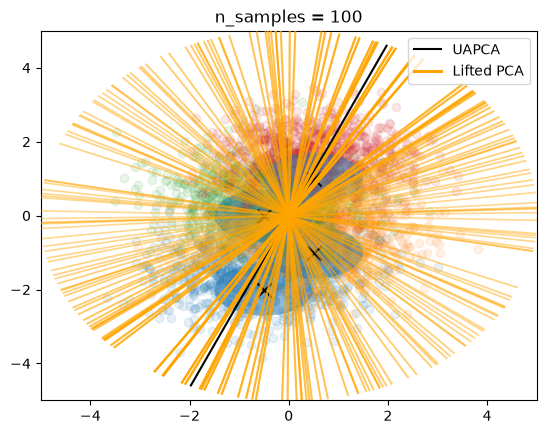

Barycenter cost: 0.06668944656848907


In [ ]:
# Fix the support and optim over weights only
lifted_pca = LiftedPCA(n_components=1, n_samples=100)
lifted_pca.fit(samples, solver="fixed_support", seed=42, n_iter_bary=1000, stop_threshold_fixed_support=1e-20)
eigenvectors_lifted = lifted_pca.components_

# Distributional PCA
pca_distributional = UAPCA()
pca_distributional.fit_from_samples(samples)
eigenvectors_distributional = pca_distributional.components_# .numpy()

plot(eigenvectors_lifted, eigenvectors_distributional, lifted_pca.center_data(samples), means, Sigmas,
     title="n_samples = "+str(100), weights=lifted_pca.weights_.numpy())

print("Barycenter cost:", lifted_pca.cost_barycenter(samples).item())

In [14]:
lifted_pca.weights_

tensor([0.0116, 0.0095, 0.0090, 0.0139, 0.0094, 0.0173, 0.0115, 0.0072, 0.0061,
        0.0068, 0.0083, 0.0192, 0.0150, 0.0191, 0.0063, 0.0103, 0.0098, 0.0117,
        0.0081, 0.0097, 0.0065, 0.0105, 0.0088, 0.0076, 0.0109, 0.0156, 0.0096,
        0.0134, 0.0061, 0.0122, 0.0127, 0.0077, 0.0094, 0.0067, 0.0066, 0.0078,
        0.0101, 0.0154, 0.0076, 0.0073, 0.0130, 0.0080, 0.0145, 0.0061, 0.0065,
        0.0066, 0.0083, 0.0074, 0.0063, 0.0061, 0.0135, 0.0066, 0.0107, 0.0080,
        0.0164, 0.0135, 0.0062, 0.0066, 0.0063, 0.0082, 0.0127, 0.0159, 0.0071,
        0.0092, 0.0087, 0.0118, 0.0123, 0.0130, 0.0061, 0.0066, 0.0099, 0.0070,
        0.0071, 0.0133, 0.0066, 0.0062, 0.0182, 0.0104, 0.0064, 0.0065, 0.0062,
        0.0124, 0.0097, 0.0114, 0.0067, 0.0061, 0.0066, 0.0185, 0.0175, 0.0068,
        0.0196, 0.0081, 0.0184, 0.0063, 0.0065, 0.0066, 0.0100, 0.0113, 0.0194,
        0.0061])

In [15]:
print(lifted_pca.weights_.max().item(), lifted_pca.weights_.min().item())

0.0195558350533247 0.006082237232476473


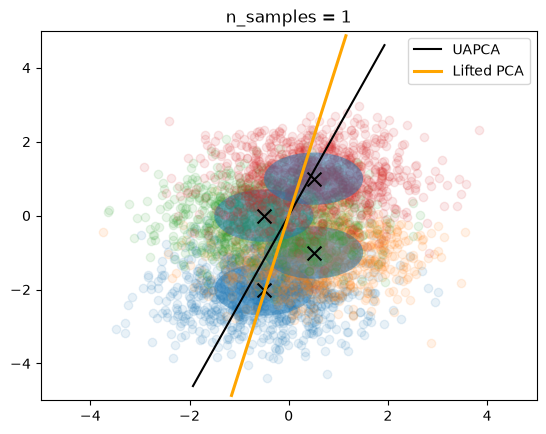

n=1 Lifted 1.1497280597686768 Distributional 1.129785418510437
[1.]


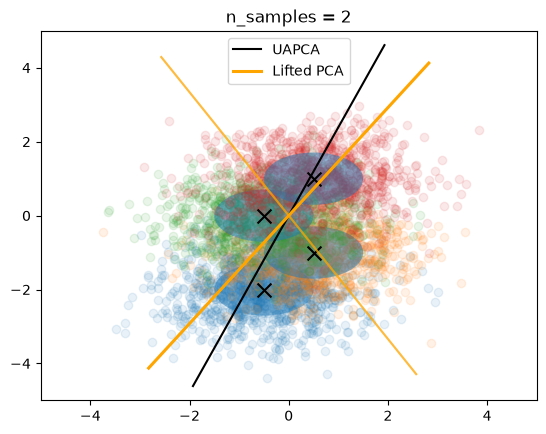

n=2 Lifted 0.5274625420570374 Distributional 1.129785418510437
[0.41072372 0.5892763 ]


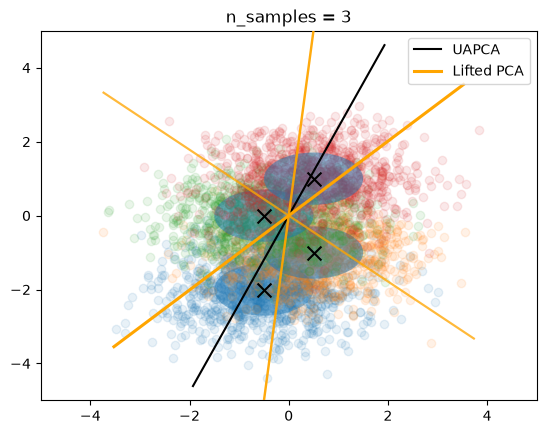

n=3 Lifted 0.3146224617958069 Distributional 1.129785418510437
[0.35153785 0.27056226 0.3778999 ]


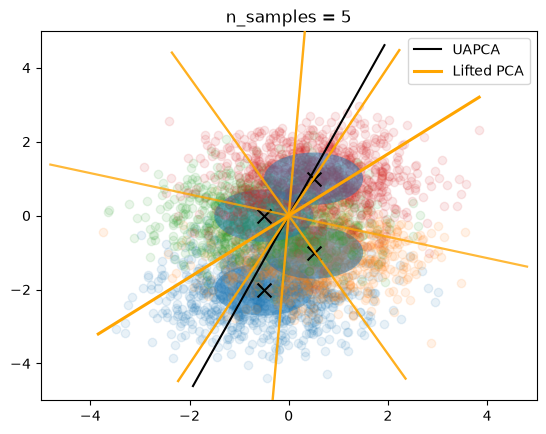

n=5 Lifted 0.1632782518863678 Distributional 1.129785418510437
[0.22708307 0.20504588 0.16417931 0.19152167 0.21217011]


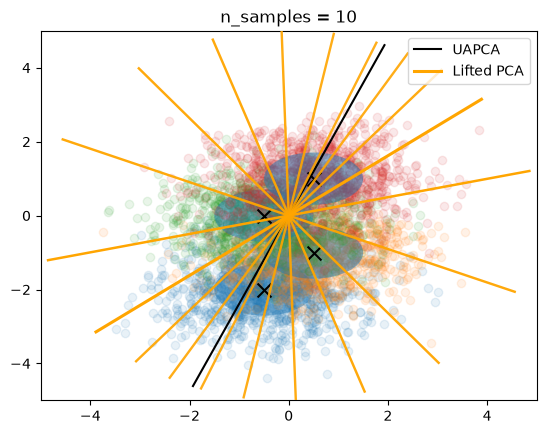

n=10 Lifted 0.0965028926730156 Distributional 1.129785418510437
[0.10709064 0.09810902 0.10143117 0.1076223  0.09477027 0.10152945
 0.10163078 0.09412614 0.09810668 0.0955836 ]


In [16]:
# Vary number of Dirac, optim over weights and support
for n_samples in [1, 2, 3, 5, 10]:
    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.fit(samples, solver="free")
    eigenvectors_lifted = lifted_pca.components_
    
    # Distributional PCA
    pca_distributional = UAPCA()
    pca_distributional.fit_from_samples(samples)
    eigenvectors_distributional = pca_distributional.components_# .numpy()

    plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas, title="n_samples = "+str(n_samples),
        weights=lifted_pca.weights_.numpy())

    print(
        "n="+str(n_samples), "Lifted", lifted_pca.cost_barycenter(samples).item(),
        "Distributional", pca_distributional.cost_barycenter(samples).item()
    )

    print(lifted_pca.weights_.numpy())

## 1 Clear PC

In [17]:
n_distr = 100

x0 = torch.zeros((n_distr, 1))
x1 = torch.randn((n_distr, 1))
means = torch.concatenate([x0, x1], axis=1)

# Mean to center full distributions (to be equivalent with PCA)
full_mean = torch.mean(means, axis=0)

# means = torch.randn((4, 2))

Sigma = torch.diag(torch.tensor([0.5, 1.5])) * 0.1
Sigmas = torch.stack([Sigma for i in range(len(means))])

# spd = SPDMatrices(2)
# samples = spd.random_point(n_samples=4)
# Sigmas = torch.from_numpy(samples).type(torch.float)

n = 50
d = 2
samples = torch.zeros((len(means), n, d))
for k in range(len(means)):
    samples[k] = means[k] + torch.randn(n, d) @ sqrtm(Sigmas[k])

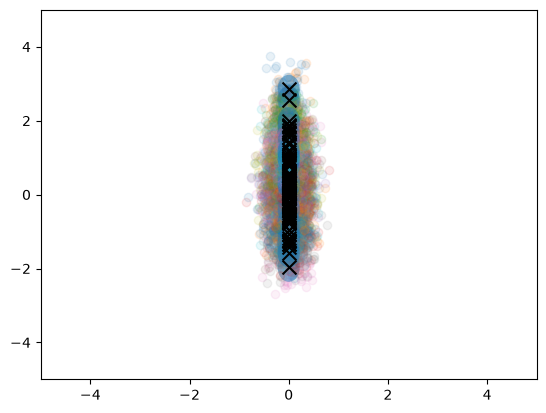

In [18]:
for k in range(len(means)):
    plt.scatter(samples[k][:, 0], samples[k][:,1], alpha=0.1)
    draw_cov(means[k], Sigmas[k], nstd=1)

plt.scatter(means[:, 0], means[:, 1], marker="x", s=100, c="k")

ts = torch.linspace(-5, 5, 100)

# for k in range(len(X_bar2)):
#     pc = ts[:,None] * X_bar2[k,:,0][None]
#     plt.plot(pc[:,0], pc[:,1], c="orange")

plt.xlim(-5, 5)
plt.ylim(-5, 5)
plt.show()

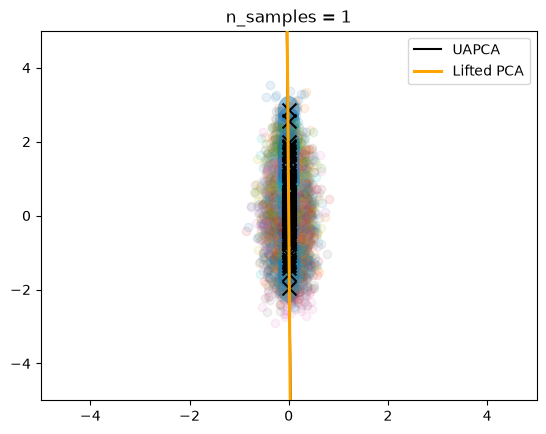

n=1 Lifted 0.050515349954366684 Distributional 0.05051345005631447


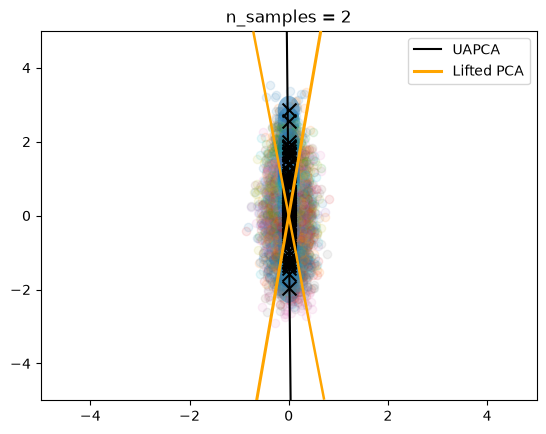

n=2 Lifted 0.030163545161485672 Distributional 0.05051345005631447


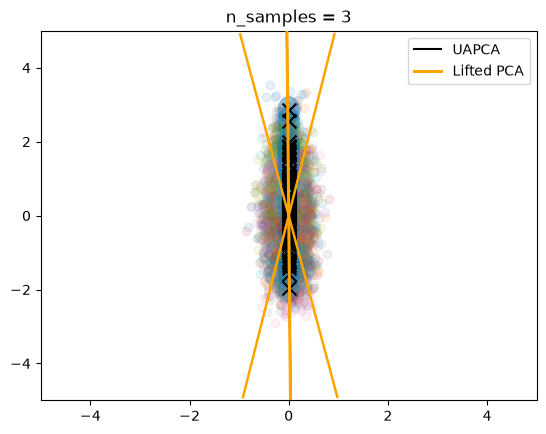

n=3 Lifted 0.024381624534726143 Distributional 0.05051345005631447


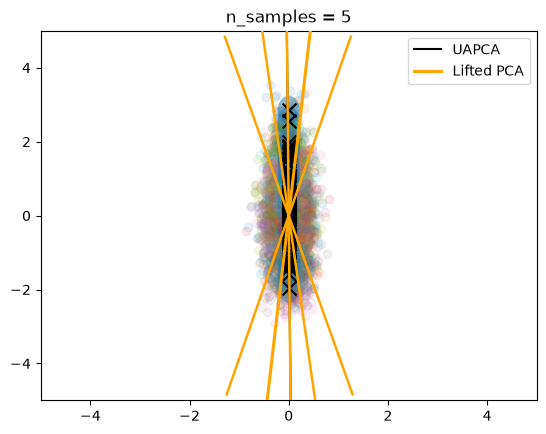

n=5 Lifted 0.02019926719367504 Distributional 0.05051345005631447


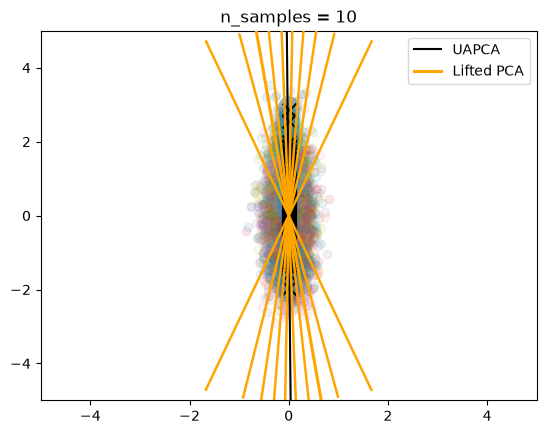

n=10 Lifted 0.017461009323596954 Distributional 0.05051345005631447


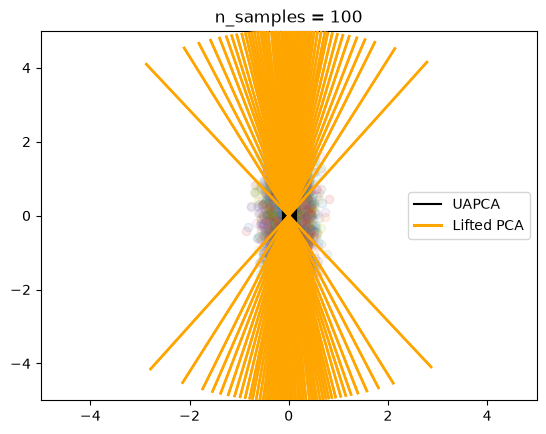

n=100 Lifted 0.015544692054390907 Distributional 0.05051345005631447


In [19]:
# Vary number of Dirac
for n_samples in [1, 2, 3, 5, 10, 100]:
    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.fit(samples)
    eigenvectors_lifted = lifted_pca.components_
    
    # Distributional PCA
    pca_distributional = UAPCA()
    pca_distributional.fit_from_samples(samples)
    eigenvectors_distributional = pca_distributional.components_# .numpy()

    plot(eigenvectors_lifted, eigenvectors_distributional, lifted_pca.center_data(samples),
         means, Sigmas, title="n_samples = "+str(n_samples))

    print(
        "n="+str(n_samples), "Lifted", lifted_pca.cost_barycenter(samples).item(),
        "Distributional", pca_distributional.cost_barycenter(samples).item()
    )

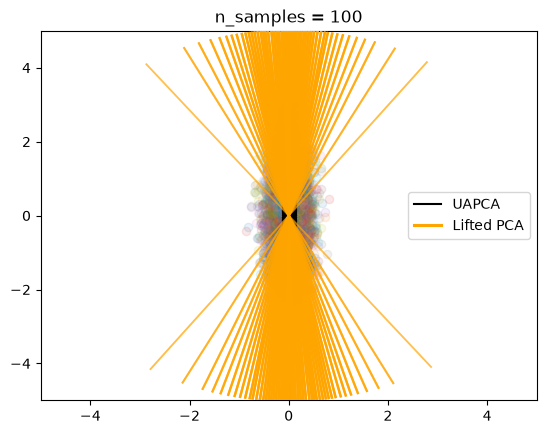

0.016529439017176628


In [20]:
# Fix the support and optim over weights only (with good initialization)
lifted_pca = LiftedPCA(n_components=1, n_samples=100)
lifted_pca.fit(samples, eigenvectors_lifted, solver="fixed_support", n_iter_bary=500, stop_threshold_fixed_support=1e-20)
eigenvectors_lifted = lifted_pca.components_

# Distributional PCA
pca_distributional = UAPCA()
pca_distributional.fit_from_samples(samples)
eigenvectors_distributional = pca_distributional.components_# .numpy()

plot(eigenvectors_lifted, eigenvectors_distributional, lifted_pca.center_data(samples), means, Sigmas,
     title="n_samples = "+str(100), weights=lifted_pca.weights_.numpy())

print(lifted_pca.cost_barycenter(samples).item())

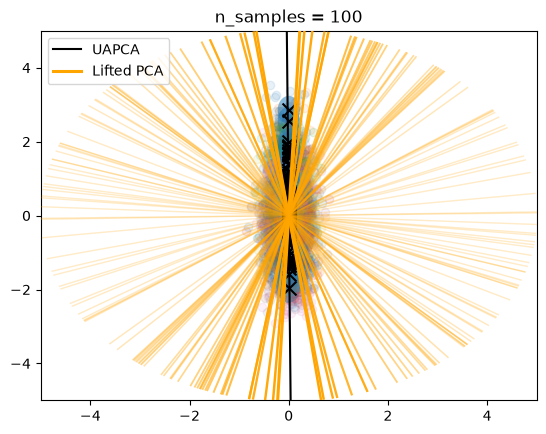

0.04431693255901337


In [21]:
# Fix the support and optim over weights only
lifted_pca = LiftedPCA(n_components=1, n_samples=100)
lifted_pca.fit(samples, solver="fixed_support", lr_bary=0.1, n_iter_bary=500, stop_threshold_fixed_support=1e-20)
eigenvectors_lifted = lifted_pca.components_

# Distributional PCA
pca_distributional = UAPCA()
pca_distributional.fit_from_samples(samples)
eigenvectors_distributional = pca_distributional.components_# .numpy()

plot(eigenvectors_lifted, eigenvectors_distributional, lifted_pca.center_data(samples), means, Sigmas,
     title="n_samples = "+str(100), weights=lifted_pca.weights_.numpy())

print(lifted_pca.cost_barycenter(samples).item())

In [22]:
lifted_pca.weights_

tensor([0.0009, 0.0073, 0.0092, 0.0256, 0.0008, 0.0373, 0.0252, 0.0119, 0.0238,
        0.0089, 0.0060, 0.0064, 0.0019, 0.0020, 0.0194, 0.0010, 0.0012, 0.0132,
        0.0243, 0.0390, 0.0304, 0.0054, 0.0010, 0.0251, 0.0181, 0.0008, 0.0011,
        0.0038, 0.0093, 0.0012, 0.0088, 0.0106, 0.0009, 0.0389, 0.0075, 0.0119,
        0.0052, 0.0341, 0.0011, 0.0397, 0.0166, 0.0009, 0.0027, 0.0060, 0.0008,
        0.0012, 0.0329, 0.0350, 0.0055, 0.0010, 0.0104, 0.0019, 0.0040, 0.0023,
        0.0173, 0.0008, 0.0148, 0.0019, 0.0158, 0.0017, 0.0175, 0.0014, 0.0015,
        0.0019, 0.0383, 0.0051, 0.0053, 0.0038, 0.0105, 0.0035, 0.0058, 0.0032,
        0.0040, 0.0020, 0.0015, 0.0008, 0.0329, 0.0008, 0.0057, 0.0037, 0.0032,
        0.0069, 0.0010, 0.0214, 0.0008, 0.0010, 0.0189, 0.0012, 0.0362, 0.0008,
        0.0018, 0.0039, 0.0027, 0.0057, 0.0159, 0.0012, 0.0076, 0.0008, 0.0038,
        0.0223])

In [23]:
print(lifted_pca.weights_.max(), lifted_pca.weights_.min())

tensor(0.0397) tensor(0.0008)


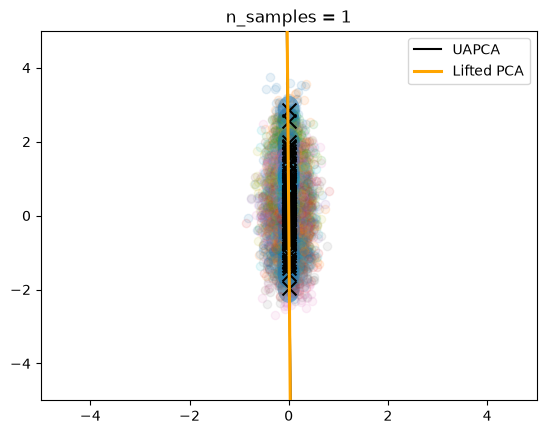

n=1 Lifted 0.050515349954366684 Distributional 0.05051345005631447
[1.]


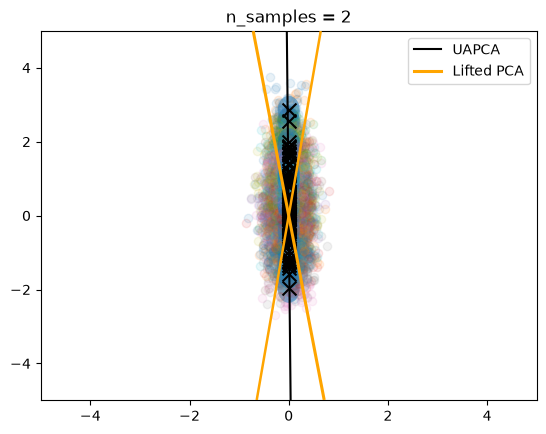

n=2 Lifted 0.030163930729031563 Distributional 0.05051345005631447
[0.49977294 0.50022715]


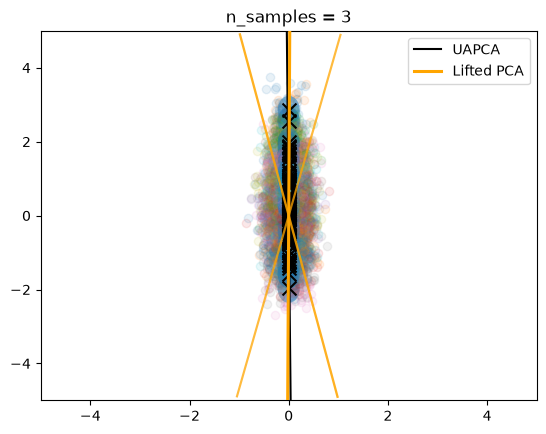

n=3 Lifted 0.023918520659208298 Distributional 0.05051345005631447
[0.27548647 0.32963198 0.39488155]


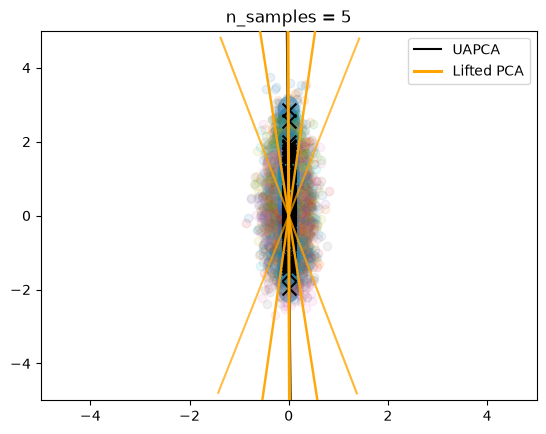

n=5 Lifted 0.01955375447869301 Distributional 0.05051345005631447
[0.15192604 0.22074756 0.22304817 0.16966091 0.23461737]


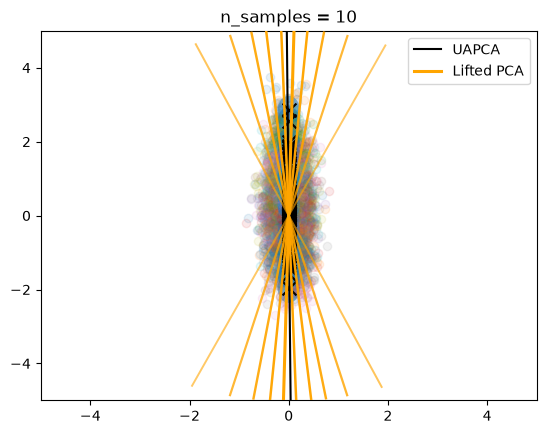

n=10 Lifted 0.016926229000091553 Distributional 0.05051345005631447
[0.10962386 0.12030596 0.09340695 0.12057249 0.11691888 0.08862517
 0.1171415  0.05942933 0.10768389 0.066292  ]


In [24]:
# Vary number of Dirac, optim over weights and support
for n_samples in [1, 2, 3, 5, 10]:
    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.fit(samples, solver="free")
    eigenvectors_lifted = lifted_pca.components_
    
    # Distributional PCA
    pca_distributional = UAPCA()
    pca_distributional.fit_from_samples(samples)
    eigenvectors_distributional = pca_distributional.components_# .numpy()

    plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas, title="n_samples = "+str(n_samples),
        weights=lifted_pca.weights_.numpy())

    print(
        "n="+str(n_samples), "Lifted", lifted_pca.cost_barycenter(samples).item(),
        "Distributional", pca_distributional.cost_barycenter(samples).item()
    )

    print(lifted_pca.weights_.numpy())

## 2 Clear PC

In [25]:
n_distr = 100

x0 = torch.zeros((n_distr//2, 1))
x1 = torch.randn((n_distr//2, 1))
means0 = torch.concatenate([x0, x1], axis=1)
means1 = torch.concatenate([x1, x0], axis=1)
means = torch.concatenate([means0, means1], axis=0)

# Mean to center full distributions (to be equivalent with PCA)
full_mean = torch.mean(means, axis=0)

Sigma0 = torch.diag(torch.tensor([0.5, 1.5])) * 0.1
Sigma1 = torch.diag(torch.tensor([1.5, 0.5])) * 0.1
Sigmas = torch.stack([Sigma0 if i<50 else Sigma1 for i in range(len(means))])

# spd = SPDMatrices(2)
# samples = spd.random_point(n_samples=4)
# Sigmas = torch.from_numpy(samples).type(torch.float)

n = 50
d = 2
samples = torch.zeros((len(means), n, d))
for k in range(len(means)):
    samples[k] = means[k] + torch.randn(n, d) @ sqrtm(Sigmas[k])

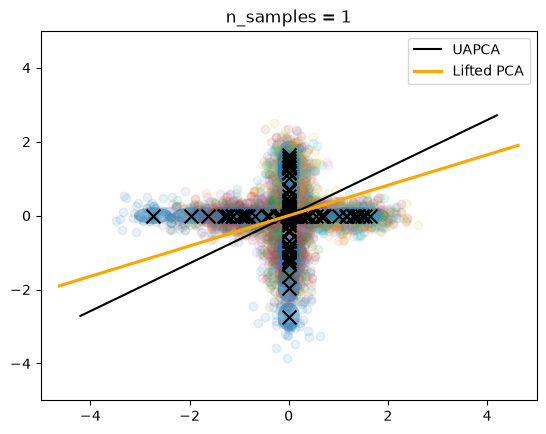

n=1 Lifted 0.6042391657829285 Distributional 0.6040632128715515


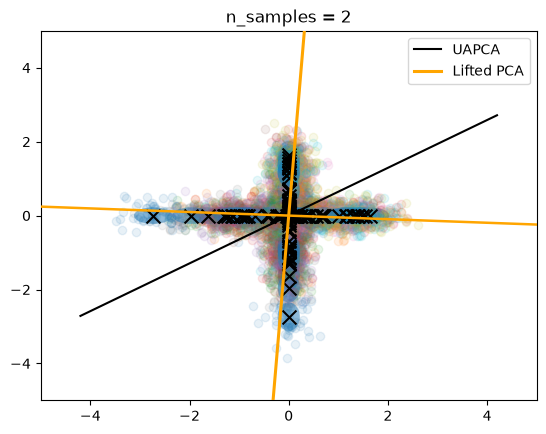

n=2 Lifted 0.34963610768318176 Distributional 0.6040632128715515


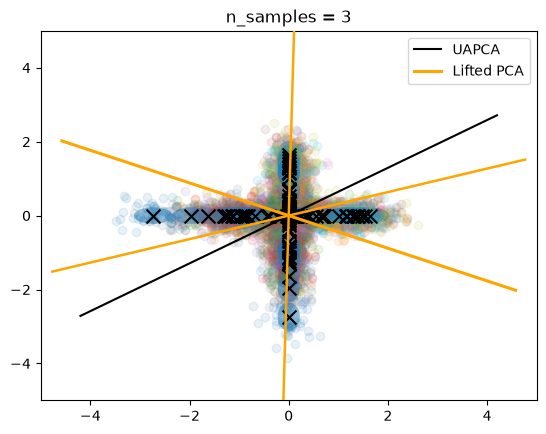

n=3 Lifted 0.33139920234680176 Distributional 0.6040632128715515


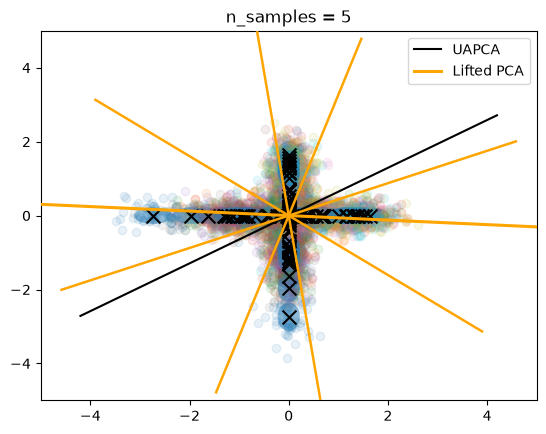

n=5 Lifted 0.29915696382522583 Distributional 0.6040632128715515


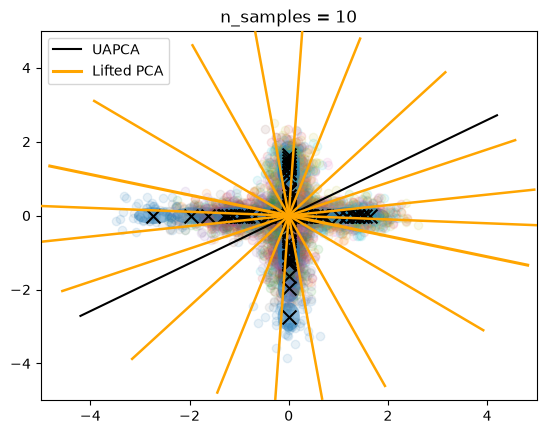

n=10 Lifted 0.28368693590164185 Distributional 0.6040632128715515


In [26]:
# Vary number of Dirac
for n_samples in [1, 2, 3, 5, 10]:
    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.fit(samples)
    eigenvectors_lifted = lifted_pca.components_
    
    # Distributional PCA
    pca_distributional = UAPCA()
    pca_distributional.fit_from_samples(samples)
    eigenvectors_distributional = pca_distributional.components_# .numpy()

    plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas, title="n_samples = "+str(n_samples))

    print(
        "n="+str(n_samples), "Lifted", lifted_pca.cost_barycenter(samples).item(),
        "Distributional", pca_distributional.cost_barycenter(samples).item()
    )

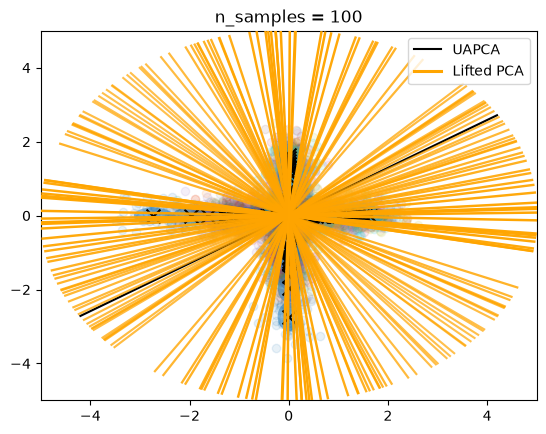

0.28150472044944763


In [27]:
# Fix the support and optim over weights only
lifted_pca = LiftedPCA(n_components=1, n_samples=100)
lifted_pca.fit(samples, solver="fixed_support", seed=42, n_iter_bary=500, stop_threshold_fixed_support=1e-20)
eigenvectors_lifted = lifted_pca.components_

# Distributional PCA
pca_distributional = UAPCA()
pca_distributional.fit_from_samples(samples)
eigenvectors_distributional = pca_distributional.components_# .numpy()

plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas,
     title="n_samples = "+str(100), weights=lifted_pca.weights_.numpy())

print(lifted_pca.cost_barycenter(samples).item())

In [28]:
lifted_pca.weights_

tensor([0.0084, 0.0095, 0.0087, 0.0124, 0.0093, 0.0114, 0.0084, 0.0077, 0.0121,
        0.0078, 0.0081, 0.0101, 0.0084, 0.0102, 0.0118, 0.0106, 0.0087, 0.0119,
        0.0079, 0.0097, 0.0085, 0.0086, 0.0084, 0.0098, 0.0085, 0.0121, 0.0096,
        0.0084, 0.0122, 0.0121, 0.0123, 0.0077, 0.0088, 0.0109, 0.0088, 0.0078,
        0.0103, 0.0122, 0.0077, 0.0102, 0.0124, 0.0095, 0.0084, 0.0121, 0.0084,
        0.0088, 0.0093, 0.0100, 0.0117, 0.0121, 0.0084, 0.0099, 0.0110, 0.0095,
        0.0118, 0.0124, 0.0120, 0.0079, 0.0117, 0.0080, 0.0123, 0.0120, 0.0104,
        0.0089, 0.0091, 0.0084, 0.0122, 0.0084, 0.0122, 0.0092, 0.0100, 0.0077,
        0.0077, 0.0084, 0.0079, 0.0120, 0.0108, 0.0106, 0.0114, 0.0083, 0.0121,
        0.0122, 0.0097, 0.0117, 0.0078, 0.0121, 0.0094, 0.0107, 0.0112, 0.0108,
        0.0095, 0.0094, 0.0107, 0.0117, 0.0112, 0.0089, 0.0101, 0.0085, 0.0092,
        0.0121])

In [29]:
lifted_pca.weights_.max()

tensor(0.0124)

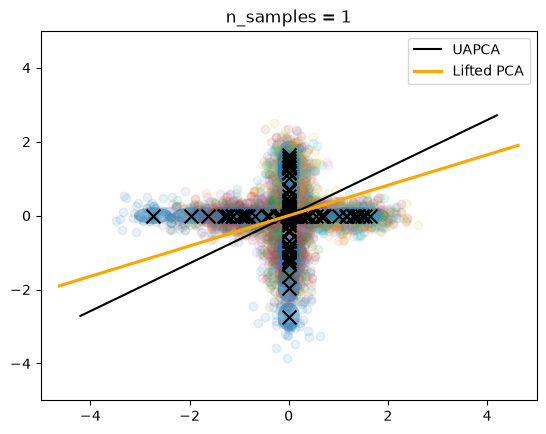

n=1 Lifted 0.6042391657829285 Distributional 0.6040632128715515
[1.]


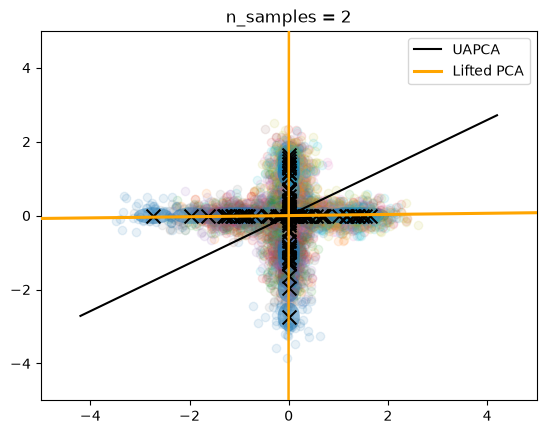

n=2 Lifted 0.3481603264808655 Distributional 0.6040632128715515
[0.49772534 0.50227475]


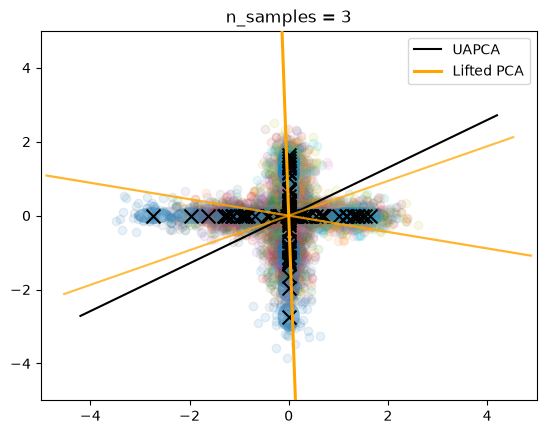

n=3 Lifted 0.3225559592247009 Distributional 0.6040632128715515
[0.4100965  0.31599414 0.27390948]


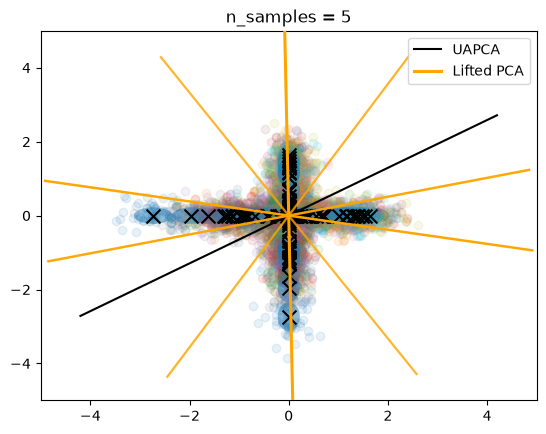

n=5 Lifted 0.29704785346984863 Distributional 0.6040632128715515
[0.21303496 0.22220084 0.22013754 0.16934082 0.17528589]


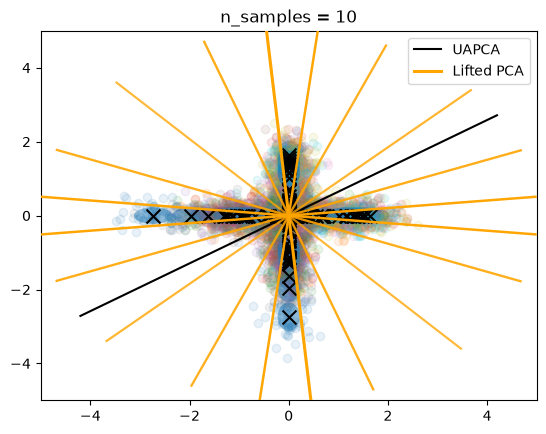

n=10 Lifted 0.28317126631736755 Distributional 0.6040632128715515
[0.11068001 0.11260116 0.08120034 0.11024074 0.0849094  0.09922214
 0.09708939 0.09512847 0.09835415 0.11057431]


In [30]:
# Vary number of Dirac, optim over weights and support
for n_samples in [1, 2, 3, 5, 10]:
    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.fit(samples, solver="free")
    eigenvectors_lifted = lifted_pca.components_
    
    # Distributional PCA
    pca_distributional = UAPCA()
    pca_distributional.fit_from_samples(samples)
    eigenvectors_distributional = pca_distributional.components_# .numpy()

    plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas, title="n_samples = "+str(n_samples),
        weights=lifted_pca.weights_.numpy())

    print(
        "n="+str(n_samples), "Lifted", lifted_pca.cost_barycenter(samples).item(),
        "Distributional", pca_distributional.cost_barycenter(samples).item()
    )

    print(lifted_pca.weights_.numpy())